# FC encoded conditions — block-wise pooled PCA and a multitask CCA latent

How the eight FC conditions (rest + 7 HCP tasks) are encoded in the shared code space of spec v4 E2
(`context_packages/repo_spec_docs/spec_doc_v4.md`, E2.0 and D2), and a first look at a multiview CCA latent across
conditions.

**Block-wise pooled PCA.** For each condition $m$, the train-split edge matrix $X^{(m)}$ is centered on its own train
mean and divided by a block scale $s_m$; the blocks are stacked (rows = subject × condition) and one PCA is taken:

$$
X_{\mathrm{pool}} = \begin{bmatrix} (X^{(\mathrm{rest})} - \mu_{\mathrm{rest}}) / s_{\mathrm{rest}} \\ \vdots \\ (X^{(\mathrm{wm})} - \mu_{\mathrm{wm}}) / s_{\mathrm{wm}} \end{bmatrix}, \qquad z^m_i = W^\top \frac{x^m_i - \mu_m}{s_m} .
$$

With $s_m = \lVert X^{(m)} - \mu_m \rVert_F$ (total-norm scaling, the E2 choice) every condition enters with the same
total variance; the alternatives are no scaling and the first singular value (multiple factor analysis).

1. Between-subject variance per condition and scan length
2. Which condition shapes which components (block contributions under three scalings)
3. Held-out variance kept: pooled vs own basis
4. The leading components: network patterns and cross-condition consistency
5. Multitask CCA latent: every subject encoded from every condition; between- vs within-subject variance; rest vs
   the multi-condition consensus

Everything is fit on the train split of one seed and evaluated on held-out (val + test) subjects.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "main.py").exists())
EXP_DIR = REPO_ROOT / "scripts" / "experiments" / "joint_flow_matching"
for p in (REPO_ROOT, EXP_DIR):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from common import CFG, load_views                      # E2 data loading (matched 917-subject cohort, v3:E0 splits)
from linear_arms import maxvar                          # E2 L4: MAXVAR multiview CCA
from models.architectures.crossmodal_flow_matching import CodeSpace

SEED = 0
K = 512                                                 # E2 k_max
FC_VIEWS = [v for v in CFG["views"] if v != "SC"]       # rest + 7 tasks
TASKS = FC_VIEWS[1:]
VOLUMES = CFG["volumes"]
SAVE_FIGURES = False
FIG_DIR = REPO_ROOT / "results/figures/fc_encoded_conditions"
COLORS = {"rest": "#0F4D92", **dict(zip(TASKS, plt.cm.tab10(np.arange(2, 9))))}

def savefig(fig, name):
    if SAVE_FIGURES:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

data, splits, subject_ids = load_views(SEED)
tr = splits["train"]
ho = np.concatenate([splits["val"], splits["test"]])
mu = {v: data[v][tr].astype(np.float64).mean(0) for v in FC_VIEWS}
Xtr = {v: data[v][tr].astype(np.float64) - mu[v] for v in FC_VIEWS}
Xho = {v: data[v][ho].astype(np.float64) - mu[v] for v in FC_VIEWS}
print(f"seed {SEED}: {len(subject_ids)} subjects | train {len(tr)} | held-out {len(ho)} | edges {data['rest'].shape[1]}")

/ext3/miniforge3/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/ext3/miniforge3/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


seed 0: 917 subjects | train 659 | held-out 258 | edges 64620


## 1. Between-subject variance per condition

Total between-subject variance of each condition's train block, $\lVert X^{(m)} - \mu_m \rVert_F^2$, against scan
length. FC estimated from fewer volumes is noisier, so short tasks carry more total variance; without scaling they
dominate any pooled PCA.

,volumes,share_of_total_variance_unscaled,first_sv_share_of_block (sv1^2 / total)
rest,4800,0.028,0.088
emotion,352,0.217,0.029
gambling,506,0.146,0.034
language,632,0.110,0.027
motor,568,0.129,0.033
relational,464,0.161,0.028
social,548,0.132,0.032
wm,810,0.077,0.028


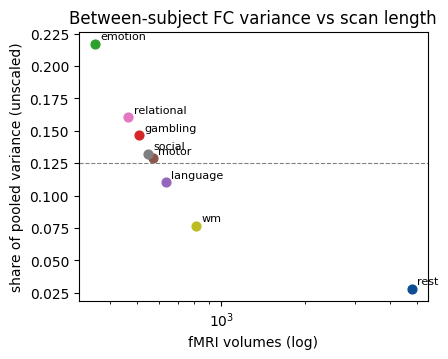

In [2]:
tot = pd.Series({v: np.square(Xtr[v]).sum() for v in FC_VIEWS})
sv1 = pd.Series({v: np.sqrt(np.linalg.eigvalsh(Xtr[v] @ Xtr[v].T)[-1]) for v in FC_VIEWS})
block_table = pd.DataFrame({
    "volumes": pd.Series(VOLUMES)[FC_VIEWS],
    "share_of_total_variance_unscaled": tot / tot.sum(),
    "first_sv_share_of_block (sv1^2 / total)": sv1 ** 2 / tot,
})
display(block_table.round(3))

fig, ax = plt.subplots(figsize=(4.5, 3.5))
for v in FC_VIEWS:
    ax.scatter(VOLUMES[v], tot[v] / tot.sum(), color=COLORS[v], s=40)
    ax.annotate(v, (VOLUMES[v], tot[v] / tot.sum()), textcoords="offset points", xytext=(4, 3), fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("fMRI volumes (log)")
ax.set_ylabel("share of pooled variance (unscaled)")
ax.axhline(1 / len(FC_VIEWS), color="grey", lw=0.8, ls="--")
ax.set_title("Between-subject FC variance vs scan length")
savefig(fig, "variance_vs_volumes")

## 2. Which condition shapes which components

For pooled component $j$ with eigenvalue $\lambda_j = \sum_m \lVert \tilde X_m w_j \rVert^2$, condition $m$'s share is
$\lVert \tilde X_m w_j \rVert^2 / \lambda_j$ (even share = 1/8). Shown for the three block scalings.

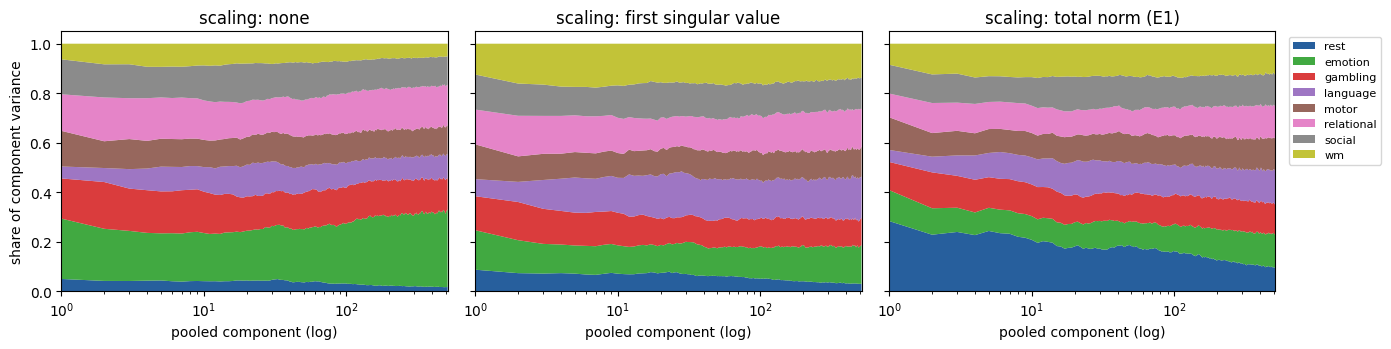

In [3]:
def pooled_basis(blocks, k):
    X = np.vstack(blocks)
    evals, U = np.linalg.eigh(X @ X.T)
    order = np.argsort(evals)[::-1][:k]
    return (X.T @ U[:, order]) / np.sqrt(evals[order])

SCALINGS = {"none": {v: 1.0 for v in FC_VIEWS}, "first singular value": sv1.to_dict(),
            "total norm (E2)": np.sqrt(tot).to_dict()}
W_by, shares_by = {}, {}
for name, s in SCALINGS.items():
    W_by[name] = pooled_basis([Xtr[v] / s[v] for v in FC_VIEWS], K)
    comp = np.stack([np.square((Xtr[v] / s[v]) @ W_by[name]).sum(0) for v in FC_VIEWS])
    shares_by[name] = pd.DataFrame(comp / comp.sum(0), index=FC_VIEWS)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
x = np.arange(1, K + 1)
for ax, (name, sh) in zip(axes, shares_by.items()):
    smooth = sh.T.rolling(10, min_periods=1).mean().T
    ax.stackplot(x, smooth.values, colors=[COLORS[v] for v in FC_VIEWS], labels=FC_VIEWS, alpha=0.9)
    ax.set_xscale("log")
    ax.set_xlim(1, K)
    ax.set_title(f"scaling: {name}")
    ax.set_xlabel("pooled component (log)")
axes[0].set_ylabel("share of component variance")
axes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.tight_layout()
savefig(fig, "block_shares_by_component")

top_k = [10, 50, 128, 256, 512]

Rest's share of the variance in the top-$k$ components (variance-weighted, so it is the share of that subspace's
total variance), per scaling:

In [4]:
def topk_share(name, k):
    s = SCALINGS[name]
    comp = np.stack([np.square((Xtr[v] / s[v]) @ W_by[name][:, :k]).sum(0) for v in FC_VIEWS]).sum(1)
    return pd.Series(comp / comp.sum(), index=FC_VIEWS)

topk_table = pd.concat({(name, k): topk_share(name, k) for name in SCALINGS for k in top_k}, axis=1).T
topk_table.index.names = ["scaling", "top k"]
display(topk_table.round(3))

rest  emotion  gambling  language  motor  \
scaling              top k                                              
none                 10     0.041    0.201     0.170     0.089  0.113   
                     50     0.041    0.205     0.155     0.104  0.117   
                     128    0.038    0.216     0.152     0.103  0.117   
                     256    0.035    0.232     0.150     0.100  0.116   
                     512    0.031    0.248     0.147     0.099  0.116   
first singular value 10     0.072    0.120     0.135     0.129  0.104   
                     50     0.070    0.119     0.122     0.150  0.106   
                     128    0.065    0.121     0.120     0.152  0.108   
                     256    0.059    0.125     0.119     0.154  0.109   
                     512    0.053    0.130     0.117     0.156  0.110   
total norm (E1)      10     0.222    0.099     0.128     0.098  0.100   
                     50     0.201    0.100     0.120     0.115  0.105   
                     128    0.189    0.102     0.120     0.117  0.109   
                     256    0.176    0.106     0.121     0.118  0.112   
                     512    0.161    0.112     0.122     0.121  0.115   

                            relational  social     wm  
scaling              top k                             
none                 10          0.162   0.137  0.086  
                     50          0.153   0.142  0.082  
                     128         0.155   0.139  0.079  
                     256         0.157   0.135  0.075  
                     512         0.160   0.131  0.070  
first singular value 10          0.146   0.129  0.166  
                     50          0.136   0.134  0.162  
                     128         0.138   0.133  0.162  
                     256         0.142   0.132  0.160  
                     512         0.147   0.130  0.156  
total norm (E1)      10          0.111   0.113  0.129  
                     50          0.106   0.123  0.130  
                     128         0.108   0.124  0.131  
                     256         0.112   0.124  0.130  
                     512         0.116   0.125  0.129

## 3. Held-out variance kept: pooled vs own basis

Share of each condition's held-out (val + test) variance captured by the first $k$ pooled components, divided by the
share captured by that condition's own train PCA. Above 1: the pooled basis generalizes better than the condition's
own (a per-task PCA on 659 short scans overfits its train split).

k=16   k=32   k=64  k=128  k=256  k=512
first singular value rest        0.812  0.868  0.910  0.942  0.971  1.013
                     emotion     1.014  1.096  1.167  1.240  1.312  1.394
                     gambling    1.023  1.074  1.131  1.189  1.245  1.322
                     language    0.829  0.924  0.994  1.047  1.099  1.171
                     motor       0.959  1.013  1.081  1.153  1.220  1.295
                     relational  1.017  1.077  1.141  1.202  1.266  1.354
                     social      0.894  0.958  1.027  1.086  1.139  1.204
                     wm          0.973  1.028  1.073  1.136  1.182  1.247
total norm (E1)      rest        0.925  0.931  0.969  0.996  1.023  1.060
                     emotion     0.998  1.090  1.169  1.245  1.320  1.408
                     gambling    1.002  1.068  1.126  1.187  1.247  1.329
                     language    0.802  0.909  0.985  1.045  1.102  1.178
                     motor       0.965  1.014  1.091  1.168  1.239  1.318
                     relational  0.992  1.062  1.127  1.194  1.259  1.354
                     social      0.884  0.957  1.027  1.090  1.148  1.216
                     wm          0.947  1.012  1.060  1.128  1.178  1.249

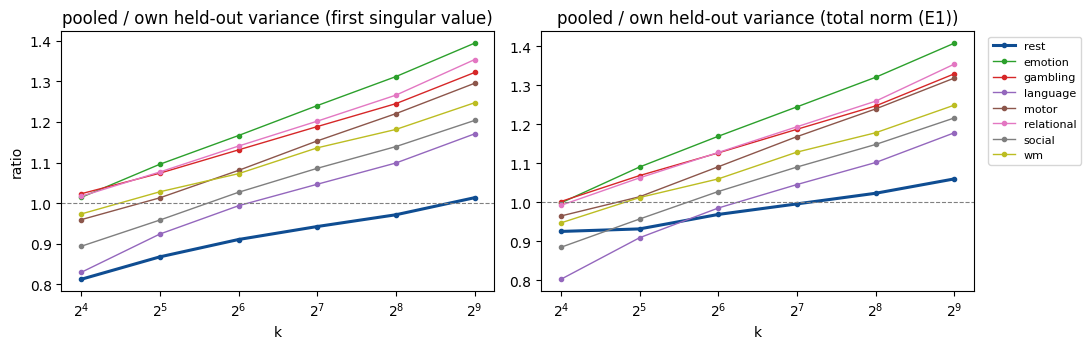

In [5]:
ks = [16, 32, 64, 128, 256, 512]
own = {v: pooled_basis([Xtr[v]], K) for v in FC_VIEWS}

def captured(X, W):
    p = np.cumsum(np.square(X @ W).sum(0)) / np.square(X).sum()
    return np.array([p[k - 1] for k in ks])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ratio_rows = {}
for name in ("first singular value", "total norm (E2)"):
    for v in FC_VIEWS:
        ratio_rows[(name, v)] = captured(Xho[v], W_by[name]) / captured(Xho[v], own[v])
ratio_table = pd.DataFrame(ratio_rows, index=[f"k={k}" for k in ks]).T
for ax, name in zip(axes, ("first singular value", "total norm (E2)")):
    for v in FC_VIEWS:
        ax.plot(ks, ratio_table.loc[name].loc[v], marker="o", ms=3, color=COLORS[v], label=v, lw=2.2 if v == "rest" else 1)
    ax.axhline(1, color="grey", lw=0.8, ls="--")
    ax.set_xscale("log", base=2)
    ax.set_xlabel("k")
    ax.set_title(f"pooled / own held-out variance ({name})")
axes[0].set_ylabel("ratio")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.tight_layout()
savefig(fig, "heldout_pooled_vs_own")
display(ratio_table.round(3))

## 4. The leading components

Loadings of the first pooled components (total-norm basis) averaged within and between Yeo-7 networks (sign oriented
so the loading correlates positively with the group-mean FC), and how consistent a held-out subject's score is across
conditions (correlation of their rest score with their score in each task).

Held-out correlation of each subject's rest score with their task score:


,PC1,PC2,PC3,PC4
emotion,0.20,-0.03,-0.06,0.22
gambling,0.25,-0.02,-0.08,0.32
language,0.17,0.06,0.09,0.20
motor,0.16,-0.02,0.18,0.13
relational,0.25,0.01,-0.06,0.18
social,0.24,0.14,-0.09,0.16
wm,0.16,0.00,-0.09,0.29


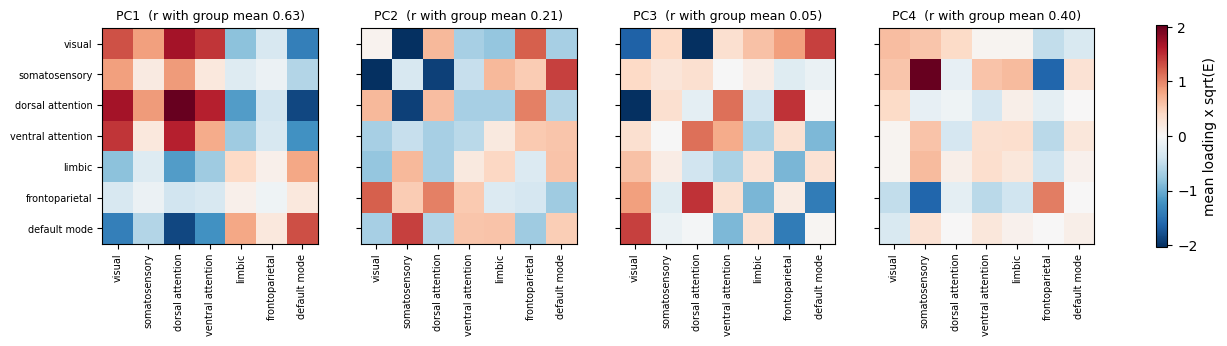

In [6]:
roi = pd.read_csv(REPO_ROOT / "data" / "atlas_info" / f"{CFG['parcellation']}_dseg_reformatted.csv")
net = roi["community_yeo"].fillna("none").to_numpy()
nets = [n for n in ["visual", "somatosensory", "dorsal attention", "ventral attention", "limbic", "frontoparietal",
                    "default mode"] if n in set(net)]
iu = np.triu_indices(len(roi), k=1)
W = W_by["total norm (E2)"]
group_mean = np.mean([mu[v] for v in FC_VIEWS], axis=0)
N_SHOW = 4

fig, axes = plt.subplots(1, N_SHOW, figsize=(4 * N_SHOW, 3.6))
consistency = {}
for j, ax in enumerate(axes):
    w = W[:, j] * np.sign(W[:, j] @ group_mean)
    B = np.full((len(nets), len(nets)), np.nan)
    for a, na in enumerate(nets):
        for b, nb in enumerate(nets):
            m = ((net[iu[0]] == na) & (net[iu[1]] == nb)) | ((net[iu[0]] == nb) & (net[iu[1]] == na))
            B[a, b] = w[m].mean() * np.sqrt(len(w))
    lim = np.nanmax(np.abs(B))
    im = ax.imshow(B, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_xticks(range(len(nets)), nets, rotation=90, fontsize=7)
    ax.set_yticks(range(len(nets)), nets if j == 0 else [""] * len(nets), fontsize=7)
    ax.set_title(f"PC{j + 1}  (r with group mean {np.corrcoef(w, group_mean)[0, 1]:.2f})", fontsize=9)
    scores = {v: Xho[v] / np.sqrt(tot[v]) @ w for v in FC_VIEWS}
    consistency[f"PC{j + 1}"] = {t: np.corrcoef(scores["rest"], scores[t])[0, 1] for t in TASKS}
fig.colorbar(im, ax=axes, shrink=0.8, label="mean loading x sqrt(E)")
savefig(fig, "leading_pc_networks")
print("Held-out correlation of each subject's rest score with their task score:")
display(pd.DataFrame(consistency).round(2))

## 5. Multitask CCA latent

MAXVAR multiview CCA (E2 reference L4) over the eight FC conditions: train codes $Z_m$ ($k$ = 128, total-norm pooled
basis) give shared subject scores $G$ ($G^\top G = I$, $d$ dimensions) and a regularized encoder $A_m$ per condition
with $Z_m A_m \approx G$. Every held-out subject is then encoded **from each condition separately**,
$g^m_i = z^m_i A_m$, giving eight points per subject in one latent space.

Questions:
- how much of the latent variance is **between subjects** (shared across a subject's conditions) vs **within
  subjects** (condition-specific), per latent dimension, compared with the same decomposition in pooled-PCA codes;
- how far a subject's **rest** encoding is from their **multi-condition consensus** (mean of the eight encodings),
  and how well rest alone identifies a subject's task encodings, in the CCA latent vs in pooled-PCA codes.

$d$ = 32 and $\lambda$ = 0.1 (relative to the mean eigenvalue of $Z_m^\top Z_m$) are the values E2's L4 selected on
val for seed 0 at $k$ = 64; they are fixed here, not tuned.

,between,within,between_share,median_dim_icc
space,,,,
CCA latent,10.193,12.208,0.455,0.444
pooled PCA codes (first d),7.166,21.182,0.253,0.252


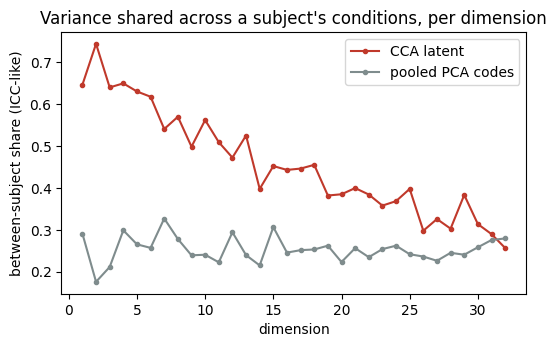

In [7]:
K_CCA, D_CCA, LAM = 128, 32, 0.1
Wc = W_by["total norm (E2)"][:, :K_CCA]
s_tot = np.sqrt(tot)
Ztr = {v: (Xtr[v] / s_tot[v]) @ Wc for v in FC_VIEWS}
Zho = {v: (Xho[v] / s_tot[v]) @ Wc for v in FC_VIEWS}
A, D, G = maxvar(Ztr, D_CCA, LAM)

enc_tr = {v: Ztr[v] @ A[v] for v in FC_VIEWS}
scale = np.concatenate(list(enc_tr.values())).std(0)
enc = {v: (Zho[v] @ A[v]) / scale for v in FC_VIEWS}            # held-out, (n_ho, d) per condition
pca_codes = {v: Zho[v][:, :D_CCA] / np.concatenate([Ztr[u][:, :D_CCA] for u in FC_VIEWS]).std(0) for v in FC_VIEWS}

def between_within(E):
    # E: {condition: (n, d)}. Per dimension: between-subject variance of subject means, mean within-subject variance
    S = np.stack([E[v] for v in FC_VIEWS])                      # (C, n, d)
    S = S - S.mean(axis=(0, 1), keepdims=True)
    between = S.mean(0).var(0)
    within = S.var(0).mean(0)
    return between, within

rows = []
for space, E in (("CCA latent", enc), ("pooled PCA codes (first d)", pca_codes)):
    b, w = between_within(E)
    rows.append(dict(space=space, between=b.sum(), within=w.sum(), between_share=b.sum() / (b.sum() + w.sum()),
                     median_dim_icc=np.median(b / (b + w))))
display(pd.DataFrame(rows).set_index("space").round(3))

fig, ax = plt.subplots(figsize=(6, 3.4))
for space, E, c in (("CCA latent", enc, "#C0392B"), ("pooled PCA codes", pca_codes, "#7F8C8D")):
    b, w = between_within(E)
    ax.plot(np.arange(1, D_CCA + 1), b / (b + w), marker="o", ms=3, color=c, label=space)
ax.set_xlabel("dimension")
ax.set_ylabel("between-subject share (ICC-like)")
ax.set_title("Variance shared across a subject's conditions, per dimension")
ax.legend()
savefig(fig, "cca_between_within")

In [8]:
from models.eval.metrics import compute_corr_matrix, corr_avg_rank, corr_topn_accuracy

def ident(src, tgt):
    cc = compute_corr_matrix(tgt - tgt.mean(0), src - src.mean(0))
    return corr_topn_accuracy(cc=cc, topn=1), corr_avg_rank(cc=cc)

rows = []
for space, E in (("CCA latent", enc), ("pooled PCA codes (first d)", pca_codes),
                 ("pooled PCA codes (k=128)", {v: Zho[v] for v in FC_VIEWS})):
    consensus_wo = {t: np.mean([E[v] for v in FC_VIEWS if v != t], axis=0) for t in TASKS}
    for t in TASKS:
        t1, r = ident(E["rest"], E[t])
        t1c, rc = ident(consensus_wo[t], E[t])
        rows.append(dict(space=space, task=t, rest_top1=t1, rest_avg_rank=r, others_top1=t1c, others_avg_rank=rc))
ident_table = pd.DataFrame(rows)
display(ident_table.groupby("space")[["rest_top1", "rest_avg_rank", "others_top1", "others_avg_rank"]].mean().round(3))
display(ident_table.pivot(index="task", columns="space", values="rest_top1").round(3))

,rest_top1,rest_avg_rank,others_top1,others_avg_rank
space,,,,
CCA latent,0.462,0.971,0.617,0.986
pooled PCA codes (first d),0.055,0.768,0.126,0.863
pooled PCA codes (k=128),0.142,0.847,0.307,0.933


space,CCA latent,pooled PCA codes (first d),pooled PCA codes (k=128)
task,,,
emotion,0.295,0.027,0.078
gambling,0.434,0.050,0.116
language,0.539,0.050,0.151
motor,0.504,0.093,0.221
relational,0.357,0.058,0.112
social,0.488,0.043,0.147
wm,0.620,0.062,0.171


Identification of a held-out subject's task encoding (chance top-1 = 1/258) from their **rest** encoding, and from
the **mean of their other seven conditions** (leave-the-target-out consensus). The second asks whether pooling
conditions gives a better subject estimate than rest alone.

Below: a few held-out subjects in the first two latent dimensions, each subject's eight condition encodings (small
points), its consensus (large point) and its rest encoding (square).

Median distance of a subject's encoding from their consensus (CCA latent):


rest          3.165
emotion       3.578
gambling      3.412
language      3.414
motor         3.361
relational    3.545
social        3.386
wm            3.274
dtype: float64

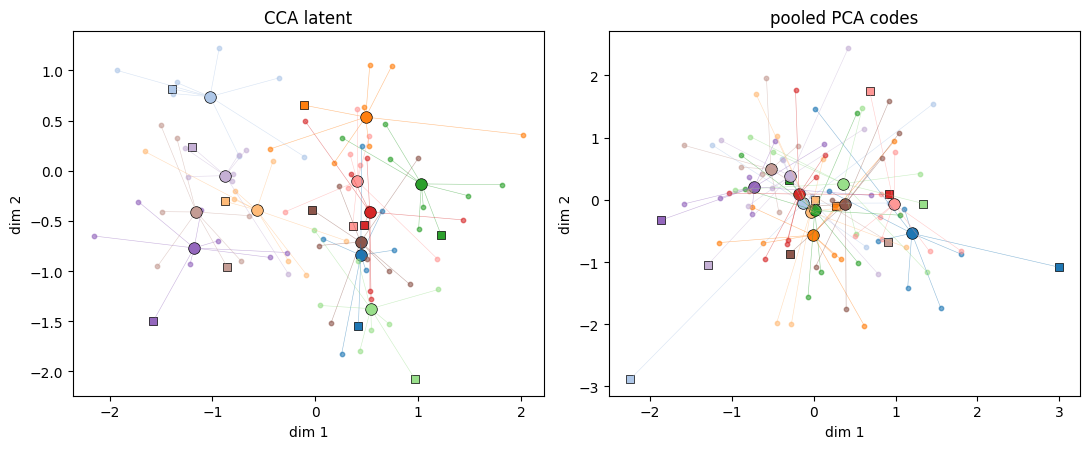

In [9]:
rng = np.random.default_rng(0)
show = rng.choice(len(ho), size=12, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (space, E) in zip(axes, (("CCA latent", enc), ("pooled PCA codes", pca_codes))):
    cmap = plt.cm.tab20(np.arange(len(show)))
    for c, i in zip(cmap, show):
        pts = np.stack([E[v][i, :2] for v in FC_VIEWS])
        ax.scatter(pts[:, 0], pts[:, 1], color=c, s=10, alpha=0.6)
        cen = pts.mean(0)
        ax.scatter(*cen, color=c, s=70, edgecolor="k", lw=0.5)
        ax.scatter(*E["rest"][i, :2], color=c, marker="s", s=40, edgecolor="k", lw=0.5)
        for p in pts:
            ax.plot([cen[0], p[0]], [cen[1], p[1]], color=c, lw=0.4, alpha=0.5)
    ax.set_title(space)
    ax.set_xlabel("dim 1")
    ax.set_ylabel("dim 2")
fig.tight_layout()
savefig(fig, "subjects_in_latent")

b, w = between_within(enc)
dist_rest = np.linalg.norm(enc["rest"] - np.mean([enc[v] for v in FC_VIEWS], axis=0), axis=1)
dist_task = {t: np.linalg.norm(enc[t] - np.mean([enc[v] for v in FC_VIEWS], axis=0), axis=1) for t in TASKS}
print("Median distance of a subject's encoding from their consensus (CCA latent):")
display(pd.Series({"rest": np.median(dist_rest), **{t: np.median(d) for t, d in dist_task.items()}}).round(3))

## Notes

- Fit on the train split of one seed; every table and figure is computed on held-out (val + test) subjects.
- The CCA latent uses the subject pairing across conditions by construction; the pooled PCA does not. Higher
  between-subject share in the CCA latent is therefore expected; the question is how much, and whether rest alone
  already sits near the consensus.
- Spec v4 E2.0 holds the corresponding numbers from the `checks/` scripts (two seeds).

## 6. Does the cross-condition FC latent transfer to SC?

A first, informal look (seed 0, not a benchmark) at whether encoding FC through the multitask CCA latent gives a better
**input** for FC → SC than plain PCA codes. SC is coded by its own train PCA ($k_{SC}$ = 256) and predicted by ridge
(penalty by generalized cross-validation on train); predictions are decoded to edges and scored on the **184 test
subjects** with the v3:E0 metrics, so the numbers sit next to `task_bidirectional_bench` (seed 0 test: rest 0.150,
WM 0.107 demeaned r). Hyperparameters ($d$, $\lambda$) are chosen on the 74 val subjects.

Inputs compared:
- **rest PCA codes** (pooled basis, $k$ = 32 / 128 / 512): the plain encoding;
- **FC-only CCA encodings** (8 FC views, never sees SC): from rest alone, from the mean of all 8 conditions
  (consensus), and from the 7 tasks without rest;
- **9-view CCA with SC as a view** (the E2 L4 model, tuned here for FC → SC): FC encoded into the joint latent and
  decoded as SC.

A last cell asks the identification question directly: in the 9-view latent, does a subject's SC encoding find their
own FC encoding among the 184 test subjects?

In [10]:
from linear_arms import ridge_gcv
from common import score

te_in_ho = np.arange(len(splits["val"]), len(ho))           # test rows within the held-out arrays
va_in_ho = np.arange(len(splits["val"]))
K_SC = 256
sc_mu = data["SC"][tr].astype(np.float64).mean(0)
Wsc = pooled_basis([data["SC"][tr].astype(np.float64) - sc_mu], K_SC)
Ysc_tr = (data["SC"][tr] - sc_mu) @ Wsc
sc_edges = {"val": data["SC"][splits["val"]], "test": data["SC"][splits["test"]]}

def fc2sc(Xin_tr, Xin_ho):
    # ridge from an FC input encoding to SC codes; returns val / test metrics on decoded SC edges
    m = Xin_tr.mean(0)
    B, a = ridge_gcv(Xin_tr - m, Ysc_tr, [float(x) for x in CFG["linear"]["ridge_alphas"]])
    pred = sc_mu + ((Xin_ho - m) @ B) @ Wsc.T
    return {s: score(pred[idx], sc_edges[s], sc_mu) for s, idx in (("val", va_in_ho), ("test", te_in_ho))}

K_FC_CCA = 256
Wf = W_by["total norm (E2)"]
Z8_tr = {v: (Xtr[v] / s_tot[v]) @ Wf[:, :K_FC_CCA] for v in FC_VIEWS}
Z8_ho = {v: (Xho[v] / s_tot[v]) @ Wf[:, :K_FC_CCA] for v in FC_VIEWS}

rows = []
def add(inp, hp, res):
    for s in ("val", "test"):
        rows.append(dict(input=inp, setting=hp, split=s, **{m: res[s][m] for m in ("demeaned_pearson", "avg_rank", "top1_acc")}))

for k in (32, 128, 512):
    add("rest PCA codes", f"k={k}", fc2sc((Xtr["rest"] / s_tot["rest"]) @ Wf[:, :k], (Xho["rest"] / s_tot["rest"]) @ Wf[:, :k]))

for d in (16, 32, 64, 128):
    for lam in (0.1, 1.0):
        A8, _, _ = maxvar(Z8_tr, d, lam)
        e_tr = {v: Z8_tr[v] @ A8[v] for v in FC_VIEWS}
        e_ho = {v: Z8_ho[v] @ A8[v] for v in FC_VIEWS}
        hp = f"d={d}, lambda={lam}"
        add("FC-only CCA: rest", hp, fc2sc(e_tr["rest"], e_ho["rest"]))
        add("FC-only CCA: consensus (8)", hp, fc2sc(np.mean([e_tr[v] for v in FC_VIEWS], 0), np.mean([e_ho[v] for v in FC_VIEWS], 0)))
        add("FC-only CCA: tasks only (7)", hp, fc2sc(np.mean([e_tr[v] for v in TASKS], 0), np.mean([e_ho[v] for v in TASKS], 0)))

res6 = pd.DataFrame(rows)
val6 = res6[res6.split == "val"].set_index(["input", "setting"])["demeaned_pearson"]
best = val6.groupby(level=0).idxmax()
summary6 = pd.concat([res6[(res6.split == "test") & (res6.input == i) & (res6.setting == s)] for i, s in best.values])
print("Test (184 subjects), each input at its val-selected setting:")
display(summary6.drop(columns="split").set_index("input").round(3))

Test (184 subjects), each input at its val-selected setting:


,setting,demeaned_pearson,avg_rank,top1_acc
input,,,,
FC-only CCA: consensus (8),"d=64, lambda=0.1",0.147,0.900,0.109
FC-only CCA: rest,"d=32, lambda=0.1",0.131,0.860,0.136
FC-only CCA: tasks only (7),"d=32, lambda=0.1",0.139,0.860,0.120
rest PCA codes,k=512,0.115,0.835,0.109


In [11]:
# 9-view CCA with SC as a view (E2 L4), tuned for FC -> SC on val; plus direct SC <-> FC identification in the latent
Ysc_ho = (data["SC"][ho] - sc_mu) @ Wsc
sc_scale = np.linalg.norm(data["SC"][tr] - sc_mu)          # total-norm scaling, as for the FC blocks
Z9_tr = dict(Z8_tr, SC=Ysc_tr / sc_scale)
Z9_ho = dict(Z8_ho, SC=Ysc_ho / sc_scale)

rows9 = []
for d in (16, 32, 64, 128):
    for lam in (0.1, 1.0):
        A9, D9, _ = maxvar(Z9_tr, d, lam)
        for src in ("rest", "wm", "consensus (8)"):
            g = np.mean([Z9_ho[v] @ A9[v] for v in FC_VIEWS], 0) if src.startswith("consensus") else Z9_ho[src] @ A9[src]
            pred = sc_mu + sc_scale * ((g @ D9["SC"]) @ Wsc.T)
            for s, idx in (("val", va_in_ho), ("test", te_in_ho)):
                m = score(pred[idx], sc_edges[s], sc_mu)
                rows9.append(dict(source=src, setting=f"d={d}, lambda={lam}", split=s,
                                  **{k: m[k] for k in ("demeaned_pearson", "avg_rank", "top1_acc")}))
        # identification in the latent: SC encoding vs rest / consensus encoding, test subjects only
        g_sc = (Z9_ho["SC"] @ A9["SC"])[te_in_ho]
        for src in ("rest", "consensus (8)"):
            g = (np.mean([Z9_ho[v] @ A9[v] for v in FC_VIEWS], 0) if src.startswith("consensus") else Z9_ho[src] @ A9[src])[te_in_ho]
            t1, r = ident(g, g_sc)
            rows9.append(dict(source=f"latent ID: SC enc. vs {src} enc.", setting=f"d={d}, lambda={lam}", split="test",
                              top1_acc=t1, avg_rank=r))
res9 = pd.DataFrame(rows9)
v9 = res9[res9.split == "val"].set_index(["source", "setting"])["demeaned_pearson"]
best9 = v9.groupby(level=0).idxmax()
print("9-view CCA (SC as a view), FC -> SC decoded, test at the val-selected setting:")
display(pd.concat([res9[(res9.split == "test") & (res9.source == s) & (res9.setting == h)] for s, h in best9.values])
        .drop(columns="split").set_index("source").round(3))
print("Identification of SC from FC inside the 9-view latent (test, 184 subjects; chance top-1 0.005):")
display(res9[res9.source.str.startswith("latent ID")].pivot(index="setting", columns="source", values=["top1_acc", "avg_rank"]).round(3))

9-view CCA (SC as a view), FC -> SC decoded, test at the val-selected setting:


,setting,demeaned_pearson,avg_rank,top1_acc
source,,,,
consensus (8),"d=32, lambda=0.1",0.144,0.880,0.136
rest,"d=32, lambda=0.1",0.135,0.864,0.125
wm,"d=32, lambda=0.1",0.114,0.804,0.076


Identification of SC from FC inside the 9-view latent (test, 184 subjects; chance top-1 0.005):


top1_acc  \
source            latent ID: SC enc. vs consensus (8) enc.   
setting                                                      
d=128, lambda=0.1                                    0.120   
d=128, lambda=1.0                                    0.136   
d=16, lambda=0.1                                     0.109   
d=16, lambda=1.0                                     0.087   
d=32, lambda=0.1                                     0.163   
d=32, lambda=1.0                                     0.114   
d=64, lambda=0.1                                     0.158   
d=64, lambda=1.0                                     0.152   

                                                   \
source            latent ID: SC enc. vs rest enc.   
setting                                             
d=128, lambda=0.1                           0.092   
d=128, lambda=1.0                           0.103   
d=16, lambda=0.1                            0.087   
d=16, lambda=1.0                            0.082   
d=32, lambda=0.1                            0.103   
d=32, lambda=1.0                            0.147   
d=64, lambda=0.1                            0.120   
d=64, lambda=1.0                            0.190   

                                                  avg_rank  \
source            latent ID: SC enc. vs consensus (8) enc.   
setting                                                      
d=128, lambda=0.1                                    0.868   
d=128, lambda=1.0                                    0.888   
d=16, lambda=0.1                                     0.829   
d=16, lambda=1.0                                     0.821   
d=32, lambda=0.1                                     0.860   
d=32, lambda=1.0                                     0.855   
d=64, lambda=0.1                                     0.880   
d=64, lambda=1.0                                     0.881   

                                                   
source            latent ID: SC enc. vs rest enc.  
setting                                            
d=128, lambda=0.1                           0.846  
d=128, lambda=1.0                           0.869  
d=16, lambda=0.1                            0.806  
d=16, lambda=1.0                            0.811  
d=32, lambda=0.1                            0.856  
d=32, lambda=1.0                            0.841  
d=64, lambda=0.1                            0.880  
d=64, lambda=1.0                            0.875

## Observations (2026-10-20, seed 0, held-out subjects)

- **Unscaled, rest carries 3 % of the pooled variance** (emotion 22 %, wm 8 %): between-subject FC variance falls with
  scan length. Rest's variance is also the most concentrated (first singular value 8.8 % of its block vs ≤ 3.4 % for
  every task), which is why first-singular-value scaling leaves it small.
- **Total-norm scaling** gives rest 22 % of the top 10 and 18 % of the top 256 components, and rest keeps
  0.97–1.06 of its own-basis held-out variance at k ≥ 64; every task keeps more than in its own basis from k = 64 (language from k = 128).
- **Leading pooled components are only weakly trait-like:** a subject's rest score predicts their task score at
  r ≤ 0.32 (PC1 0.16–0.25; PCs 2–3 near zero).
- **The multitask CCA latent concentrates subject-shared variance:** 46 % of its variance is between subjects vs 25 %
  for the same number of pooled-PCA dimensions.
- **Identification across conditions is far better in the CCA latent** (chance top-1 = 0.004): a subject's rest
  encoding finds their task encoding at top-1 0.46 on average (0.30 emotion to 0.62 wm; average rank 0.97), against
  0.06 in the first 32 pooled-PCA codes and 0.14 in all 128. The mean of the other seven conditions does better than
  rest alone (top-1 0.62 vs 0.46), so pooling conditions improves the subject estimate.
- Rest sits closest to the consensus (median distance 3.17 vs 3.27–3.58 for tasks), consistent with it being the most
  reliable single view.
- **FC → SC through the CCA latent (section 6, seed 0, 184 test subjects, ridge readout):**
  - FC-only CCA (never sees SC) beats plain PCA codes as the input: rest 0.131 vs 0.115 demeaned r (rest PCA codes,
    k = 512, same ridge).
  - The **8-condition consensus** reaches 0.147 demeaned r and average rank 0.900, against the tuned
    `task_bidirectional_bench` rest model at 0.150 / 0.860 / top-1 0.109 on the same split.
  - **Tasks alone (7, no rest)** give 0.139, above rest alone in the same latent (0.131) and above every single-task
    bench row (best WM 0.107): the shared task signal carries SC-relevant information that per-task models miss.
  - With SC as a 9th CCA view, results are similar (consensus 0.144, rest 0.135), and inside that latent a subject's
    SC encoding identifies their FC encoding at top-1 up to 0.16–0.19 (chance 0.005).
  - Caveats: one seed; settings chosen on 74 val subjects; differences of ~0.01 are within seed-to-seed spread; FC → SC
    rank / top-1 read with v3:C!2 (parcel geometry); a formal multi-seed benchmark is needed.
- Caveats (sections 1–5): one seed; CCA $d$ and $\lambda$ fixed, not tuned; the CCA uses subject pairing across conditions on the
  train split by construction (held-out subjects are never seen).
